# Improving the two models you can explain: depth-4 tree and logistic regression 🩺

Self-contained. Run the cells **from top to bottom**. It only **reads** `data/praxisnow_appointments.csv`.
Put this file in the same folder as your original notebook (the folder that contains `data/`).

**Plan:** 1) rebuild the old models as a reference, 2) add features, 3) tune hyperparameters with a time-aware split, 4) test once, 5) look inside both models.

## Step 1 · Load, split by date, and the old models as reference

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.metrics import roc_auc_score, recall_score, precision_score

appointments = pd.read_csv("data/praxisnow_appointments.csv", parse_dates=["booked_at", "appointment_at"])
appointments["lead_days"] = (appointments["appointment_at"].dt.normalize() - appointments["booked_at"]).dt.days
appointments["weekday"] = appointments["appointment_at"].dt.day_name()
appointments["hour"] = appointments["appointment_at"].dt.hour

# no leaky columns: wait_time_min and reminder_reply are NOT used
features = ["lead_days", "weekday", "hour", "clinic_city", "specialty", "booking_channel",
            "age", "insurance", "distance_km", "sms_opt_in", "prior_appointments", "prior_no_shows"]
numeric = ["lead_days", "hour", "age", "distance_km", "sms_opt_in", "prior_appointments", "prior_no_shows"]
categorical = ["weekday", "clinic_city", "specialty", "booking_channel", "insurance"]

cutoff = "2026-08-01"
is_train = appointments["appointment_at"] < cutoff
is_test = appointments["appointment_at"] >= cutoff
X_train, y_train = appointments.loc[is_train, features], appointments.loc[is_train, "no_show"]
X_test, y_test = appointments.loc[is_test, features], appointments.loc[is_test, "no_show"]

# old recipe (scaled), exactly as in the course notebook
prep = ColumnTransformer([
    ("num", Pipeline([("fill", SimpleImputer(strategy="median", add_indicator=True)),
                      ("scale", StandardScaler())]), numeric),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical),
])
old_lr = Pipeline([("prep", clone(prep)), ("model", LogisticRegression(max_iter=1000))]).fit(X_train, y_train)
old_tree = Pipeline([("prep", clone(prep)), ("model", DecisionTreeClassifier(max_depth=4, random_state=42))]).fit(X_train, y_train)

old = {"Old logistic regression": old_lr, "Old tree (depth 4)": old_tree}
for name, m in old.items():
    print(name, "test AUC:", round(roc_auc_score(y_test, m.predict_proba(X_test)[:, 1]), 3))

Old logistic regression test AUC: 0.782
Old tree (depth 4) test AUC: 0.765


## Step 2 · New features (only things known at booking time)

Step 4 of the course showed that lead time is **not a straight line** (6% no-shows same day, 45% at 1 to 4 months). A logistic regression can only draw straight lines, so we give it help: a log version of lead time and lead-time groups.

`add_features` works on a **copy**, so your original table stays untouched.

In [2]:
def add_features(df):
    df = df.copy()
    df["lead_log"] = np.log1p(df["lead_days"])                      # flattens the long tail
    df["lead_group"] = pd.cut(df["lead_days"], [-1, 0, 2, 7, 14, 30, 120],
                              labels=["same_day", "1_2_days", "3_7_days", "1_2_weeks", "2_4_weeks", "1_4_months"]).astype(str)
    df["is_weekend"] = df["weekday"].isin(["Saturday", "Sunday"]).astype(int)
    df["has_history"] = (df["prior_appointments"] > 0).astype(int)
    # share of past appointments that were no-shows (NaN if no history -> imputer fills it)
    df["prior_no_show_rate"] = df["prior_no_shows"] / df["prior_appointments"].replace(0, np.nan)
    df["has_prior_no_show"] = (df["prior_no_shows"] > 0).astype(int)
    df["young_adult"] = (df["age"] < 30).astype(int)
    df["far_away"] = (df["distance_km"] > 15).astype(int)           # NaN distance -> 0, the missing flag still exists
    return df

X_train2, X_test2 = add_features(X_train), add_features(X_test)

numeric2 = numeric + ["lead_log", "is_weekend", "has_history", "prior_no_show_rate",
                      "has_prior_no_show", "young_adult", "far_away"]
categorical2 = categorical + ["lead_group"]

# scaled recipe for logistic regression
prep_lr = ColumnTransformer([
    ("num", Pipeline([("fill", SimpleImputer(strategy="median", add_indicator=True)),
                      ("scale", StandardScaler())]), numeric2),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical2),
])
# UNscaled recipe for the tree: trees do not need scaling, and the split values stay readable (lead_days <= 20)
prep_tree = ColumnTransformer([
    ("num", SimpleImputer(strategy="median", add_indicator=True), numeric2),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical2),
])
X_train2.head()

,lead_days,weekday,hour,clinic_city,specialty,booking_channel,age,insurance,distance_km,sms_opt_in,prior_appointments,prior_no_shows,lead_log,lead_group,is_weekend,has_history,prior_no_show_rate,has_prior_no_show,young_adult,far_away
0,6,Monday,8,Leipzig,dentistry,phone,79,public,5.3,0,0,0,1.945910,3_7_days,0,0,NaN,0,0,0
1,10,Monday,8,Berlin,physiotherapy,phone,58,public,3.0,1,0,0,2.397895,1_2_weeks,0,0,NaN,0,0,0
2,11,Monday,8,Munich,physiotherapy,website,63,private,10.7,1,0,0,2.484907,1_2_weeks,0,0,NaN,0,0,0
3,9,Monday,9,Berlin,physiotherapy,app,35,private,3.3,0,0,0,2.302585,1_2_weeks,0,0,NaN,0,0,0
4,0,Monday,9,Hamburg,general_practice,phone,71,public,1.5,0,0,0,0.000000,same_day,0,0,NaN,0,0,0


## Step 3 · Tune hyperparameters with a time-aware split

`TimeSeriesSplit` always validates on **later** appointments than it trains on. The test set is **not** used here.

- **Tree:** `max_depth` (how deep), `min_samples_leaf` (no tiny leaves), `ccp_alpha` (pruning), `criterion` (how a split is judged), `class_weight`.
- **Logistic regression:** `C` (smaller = simpler, more regularised), `penalty` (l1 can switch useless features off), `class_weight`.

In [3]:
# sort training rows by date so the folds respect time
order = appointments.loc[is_train, "appointment_at"].argsort().values
X_tr, y_tr = X_train2.iloc[order], y_train.iloc[order]
cv = TimeSeriesSplit(n_splits=4)

tree_search = GridSearchCV(
    Pipeline([("prep", clone(prep_tree)), ("model", DecisionTreeClassifier(random_state=42))]),
    param_grid={"model__max_depth": [3, 4, 5, 6],
                "model__min_samples_leaf": [10, 30, 60],
                "model__criterion": ["gini", "entropy"],
                "model__ccp_alpha": [0, 0.001, 0.003],
                "model__class_weight": [None, "balanced"]},
    scoring="roc_auc", cv=cv, n_jobs=-1,
).fit(X_tr, y_tr)

lr_search = GridSearchCV(
    Pipeline([("prep", clone(prep_lr)), ("model", LogisticRegression(solver="liblinear", max_iter=2000))]),
    param_grid={"model__C": [0.01, 0.03, 0.1, 0.3, 1, 3],
                "model__penalty": ["l1", "l2"],
                "model__class_weight": [None, "balanced"]},
    scoring="roc_auc", cv=cv, n_jobs=-1,
).fit(X_tr, y_tr)

print("Tree  CV AUC:", round(tree_search.best_score_, 3), tree_search.best_params_)
print("LogReg CV AUC:", round(lr_search.best_score_, 3), lr_search.best_params_)

/Users/xpourta/Documents/neufische/aipm-ml-praxisnow/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/Users/xpourta/Documents/neufische/aipm-ml-praxisnow/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/Users/xpourta/Documents/neufische/aipm-ml-praxisnow/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this w

Tree  CV AUC: 0.728 {'model__ccp_alpha': 0, 'model__class_weight': None, 'model__criterion': 'gini', 'model__max_depth': 6, 'model__min_samples_leaf': 60}
LogReg CV AUC: 0.782 {'model__C': 0.03, 'model__class_weight': 'balanced', 'model__penalty': 'l1'}


/Users/xpourta/Documents/neufische/aipm-ml-praxisnow/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/Users/xpourta/Documents/neufische/aipm-ml-praxisnow/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


## Step 4 · Final check on the test set (look once, after tuning)

In [4]:
new = {"New logistic regression": (lr_search.best_estimator_, X_test2),
       "New tree (tuned)": (tree_search.best_estimator_, X_test2)}
rows = []
for name, m in old.items():
    s = m.predict_proba(X_test)[:, 1]
    p = (s >= 0.5).astype(int)
    rows.append({"model": name, "test AUC": roc_auc_score(y_test, s),
                 "recall@0.5": recall_score(y_test, p), "precision@0.5": precision_score(y_test, p, zero_division=0)})
for name, (m, X) in new.items():
    s = m.predict_proba(X)[:, 1]
    p = (s >= 0.5).astype(int)
    rows.append({"model": name, "test AUC": roc_auc_score(y_test, s),
                 "recall@0.5": recall_score(y_test, p), "precision@0.5": precision_score(y_test, p, zero_division=0)})
pd.DataFrame(rows).set_index("model").round(3)

,test AUC,recall@0.5,precision@0.5
model,,,
Old logistic regression,0.782,0.286,0.609
Old tree (depth 4),0.765,0.273,0.553
New logistic regression,0.802,0.748,0.416
New tree (tuned),0.758,0.226,0.515


## Step 5 · Look inside: the tuned tree you can show Dr. Okafor

Depth: 6  Leaves: 32


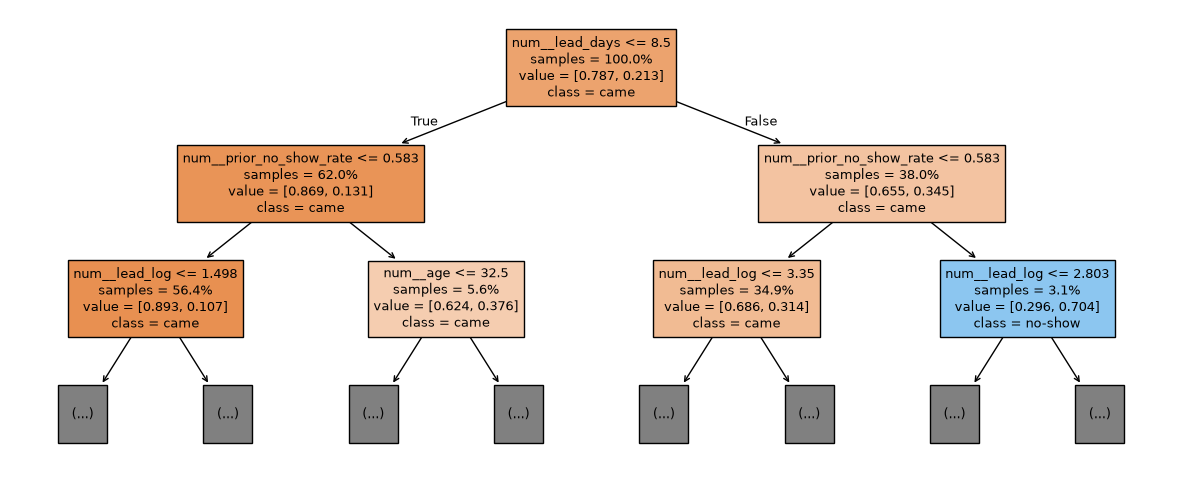

In [5]:
best_tree = tree_search.best_estimator_
names = best_tree.named_steps["prep"].get_feature_names_out()
print("Depth:", best_tree.named_steps["model"].get_depth(), " Leaves:", best_tree.named_steps["model"].get_n_leaves())
plt.figure(figsize=(15, 6))
plot_tree(best_tree.named_steps["model"], max_depth=2, feature_names=list(names),
          class_names=["came", "no-show"], filled=True, impurity=False, proportion=True, fontsize=9)
plt.show()

## Step 6 · Look inside: the tuned logistic regression weights

num__lead_log                               0.79
num__prior_no_show_rate                     0.46
num__age                                   -0.43
num__sms_opt_in                            -0.23
cat__booking_channel_phone                 -0.23
num__has_history                           -0.13
num__missingindicator_prior_no_show_rate    0.10
num__prior_no_shows                         0.04
num__prior_appointments                    -0.01
num__hour                                   0.00
num__young_adult                            0.00
cat__booking_channel_app                    0.00
dtype: float64


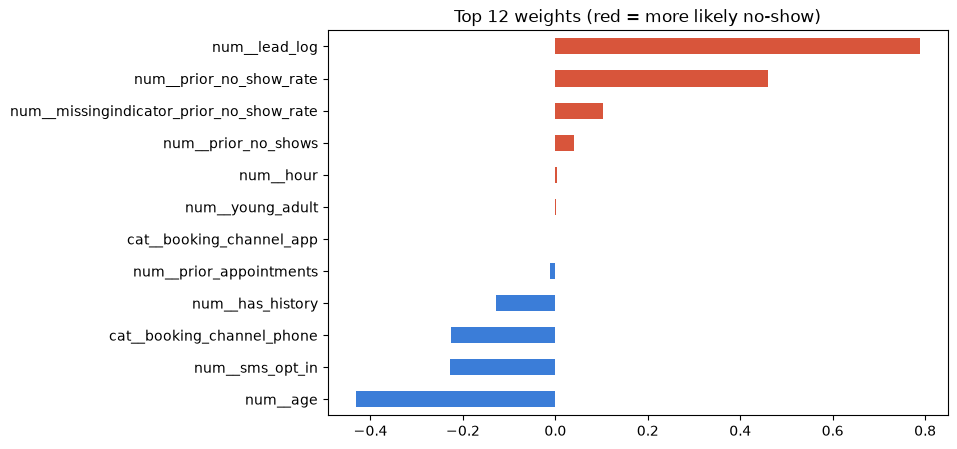

Features switched off by l1 (weight = 0): 31


In [6]:
best_lr = lr_search.best_estimator_
weights = pd.Series(best_lr.named_steps["model"].coef_[0],
                    index=best_lr.named_steps["prep"].get_feature_names_out())
top = weights.reindex(weights.abs().sort_values(ascending=False).index).head(12)
print(top.round(2))
top.sort_values().plot.barh(color=np.where(top.sort_values() > 0, "#d8553b", "#3b7dd8"), figsize=(8, 5),
                            title="Top 12 weights (red = more likely no-show)")
plt.show()
print("Features switched off by l1 (weight = 0):", int((weights == 0).sum()))

🧠 **Think:** Did the new features and tuning help the tree or the logistic regression more? If the gain is only about 0.01 AUC, is it worth the extra complexity? Which of the two would you show Dr. Okafor?

**✍️ Your answer:** *double-click here and write 1–3 sentences.*